ThinCurr Python Example: Junctions between sheets {#doc_tCurr_junctions}
==========
In this example we model conducting sheets that meet along a shared edge, a *junction*, where more than two sheets
are connected (for example a plate with a stiffening rib, or a flange welded around a tube). ThinCurr supports these
meshes by splitting the mesh along the junction, giving each sheet its own copy of the junction vertices, and then
enforcing current conservation (Kirchhoff's law) across every junction edge. Holes are chosen automatically,
including the extra loop currents created when a junction closes on itself. See \ref doc_tw_main_junctions for details.

We consider two geometries, built with [gmsh](https://gmsh.info) (`junction_meshes.py`), where each sheet is a
gmsh physical surface (a separate region):
 1. A T-shaped plate: two plate halves and a stem meeting along one edge
 2. A tube with a flange around its middle: a closed (circular) junction

For each we compare the joined model with the same sheets insulated from each other at the junction.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) and [pyvista](https://pyvista.org/) python packages, which are installable using `pip` or other standard methods.

In [1]:
import sys
import os
import numpy as np
try:
    import pyvista
    pyvista.set_jupyter_backend('static') # Comment to enable interactive PyVista plots
    have_pyvista = True
except ImportError:
    print("pyvista not found, 3D plots will be skipped")
    have_pyvista = False

## Load ThinCurr library

To load the ThinCurr python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` for binaries on macOS).

In [2]:
thincurr_python_path = os.getenv('OFT_ROOTPATH')
if thincurr_python_path is not None:
    sys.path.append(os.path.join(thincurr_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.ThinCurr import ThinCurr
from OpenFUSIONToolkit._gmsh_cli import convert_gmsh_to_native
from OpenFUSIONToolkit.ThinCurr._homology_cli import compute_homology

## T-shaped plate

### Prepare the mesh
First we convert the gmsh mesh to the native format, keeping the physical surfaces as regions (`physical_regions=True`,
or `--physical_regions` with `OFT_convert_gmsh`). Every junction edge is shared by cells from three regions.

Next we run the hole tool (\ref thincurr_holes_tool "OFT_ThinCurr_holes", here called from Python). When it finds
edges shared by more than two cells it splits the mesh at the junctions and writes the junction data needed by
ThinCurr: the junction table, the hole elements and the map from the split mesh's unknowns to the joined model's. It
also checks that the number of unknowns equals the number of independent current patterns on the original mesh.

In [3]:
convert_gmsh_to_native('thincurr_ex-tplate.msh', physical_regions=True)
compute_homology('thincurr_ex-tplate.h5')


Reading mesh: thincurr_ex-tplate.msh
  Mesh type: TRI_P1
  Dimension: 2D
  # of points  = 780 (0)
  # of cells   = 1458
  # of regions = 3

Saving mesh: thincurr_ex-tplate.h5
Junction mesh:
  # of junction lines = 1
  # of junction edges = 20
  # of vertices after split = 822
  # of holes = 1 (outer arcs and cuts)
  # of cuts = 0
  # of closures = 1
  # of unknowns = 680 (independent currents 680)

Saving mesh: thincurr_ex-tplate-homology.h5


### Setup the joined model and compute eigenvalues
The split mesh file is used like any other ThinCurr mesh. Here the surface resistivity of each region is set in `oft_in.xml`.

In [4]:
myOFT = OFT_env(nthreads=2)
tw_tplate = ThinCurr(myOFT)
tw_tplate.setup_model(mesh_file='thincurr_ex-tplate-homology.h5',xml_filename='oft_in.xml')
tw_tplate.setup_io(basepath='tplate/')
tw_tplate.compute_Lmat()
tw_tplate.compute_Rmat()
eig_vals, eig_vecs = tw_tplate.get_eigs(4,True)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.9
Development branch:  thincurr-junctions
Revision id:         e0c87b2

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------

Verifying mesh holes and closures...
Junction mesh detected, holes were chosen and checked when the junctions were split


Creating thin-wall model
  No V(t) driver coils found
  No I(t) driver coils found
  Creating hole elements
  Junctions: unknowns reduced from      699 to      680

  Loading region surface resistivity:
     1  1.2570E-05
     2  1.2570E-05
     3  1.2570E-05

  Setup complete:
    # of points    =          822
    # of edges     =         2277
    # of cells     =         1458
    # of holes     =            1
    # of cl

  Time =  3s          
Building resistivity matrix
 Inverting real matrix
   Time =    1.4059000000000000E-002

Starting eigenvalue solve (direct)


  Time =   2.6492E-01   0


  Eigenvalues
      9.736264E-03
      7.974831E-03
      7.366639E-03
      6.533022E-03


### Compare with insulated sheets
To see the effect of the junction we set up a second model in which the stem (region 3) is insulated from the
plate at the junction, using the `junction_insulated` argument of \ref OpenFUSIONToolkit.ThinCurr.ThinCurr.setup_model "setup_model()".
The holes and the reduction are recomputed for this configuration when the model is set up, so the same mesh file is used.

In [5]:
tw_tplate_gap = ThinCurr(myOFT)
tw_tplate_gap.setup_model(mesh_file='thincurr_ex-tplate-homology.h5',xml_filename='oft_in.xml',junction_insulated=[3])
tw_tplate_gap.setup_io(basepath='tplate_gap/')
tw_tplate_gap.compute_Lmat()
tw_tplate_gap.compute_Rmat()
eig_vals_gap, _ = tw_tplate_gap.get_eigs(4,True)
print('Unknowns: joined {0}, stem insulated {1}'.format(tw_tplate.nelems, tw_tplate_gap.nelems))
print('Decay times [ms]')
print('  joined:         ', np.round(1.E3*eig_vals, 4))
print('  stem insulated: ', np.round(1.E3*eig_vals_gap, 4))

Verifying mesh holes and closures...
Junction mesh detected, holes were chosen and checked when the junctions were split


Creating thin-wall model
  No V(t) driver coils found
  No I(t) driver coils found
  Creating hole elements
  Junctions: unknowns reduced from      680 to      661

  Loading region surface resistivity:
     1  1.2570E-05
     2  1.2570E-05
     3  1.2570E-05

  Setup complete:
    # of points    =          822
    # of edges     =         2277
    # of cells     =         1458
    # of holes     =            1
    # of closures  =            0
    # of Vcoils    =            0
    # of Icoils    =            0


Building element<->element self inductance matrix


  Time =  3s          
Building resistivity matrix
 Inverting real matrix
   Time =    1.4955000000000000E-002

Starting eigenvalue solve (direct)


  Time =   3.6970E-01   0
Unknowns: joined 680, stem insulated 661
Decay times [ms]
  joined:          [9.7363 7.9748 7.3666 6.533 ]
  stem insulated:  [9.7363 7.8122 6.533  5.9123]


  Eigenvalues
      9.736263E-03
      7.812187E-03
      6.533022E-03
      5.912346E-03


The slowest mode is a plate mode that does not involve the stem and is the same in both models. The second and
third modes of the joined model exist only because current can cross the junction: the stem's current divides
between the two plate halves.

### Plot current in a junction mode


Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thincurr
    Found Mesh: smesh


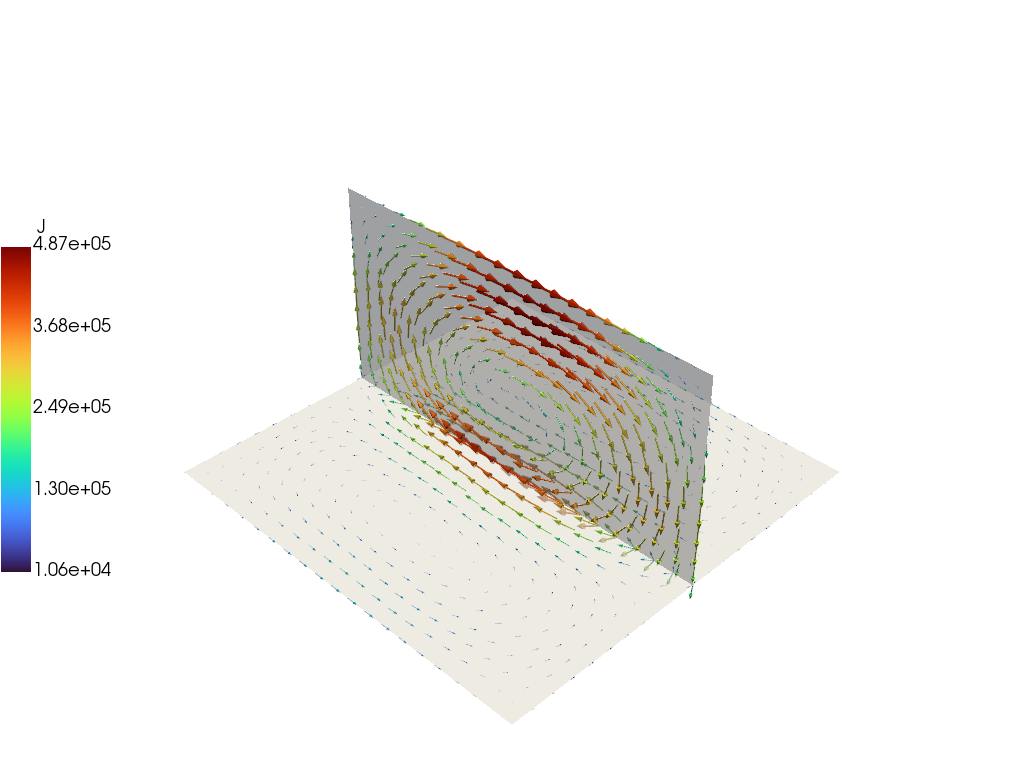

In [6]:
tw_tplate.save_current(eig_vecs[1,:],'J_02')
plot_data = tw_tplate.build_XDMF()
if have_pyvista:
    grid = plot_data['ThinCurr']['smesh'].get_pyvista_grid()
    J_02 = plot_data['ThinCurr']['smesh'].get_field('J_02_v')
    grid["vectors"] = J_02
    grid.set_active_vectors("vectors")
    p = pyvista.Plotter()
    scale = 0.1/(np.linalg.norm(J_02,axis=1)).max()
    arrows = grid.glyph(scale="vectors", orient="vectors", factor=scale)
    p.add_mesh(arrows, cmap="turbo", scalar_bar_args={'title': "J", "vertical": True, "position_y":0.25, "position_x": 0.0})
    p.add_mesh(grid, color="white", opacity=0.6, show_edges=False)
    p.show(jupyter_backend='static')

## Tube with a flange

When a junction closes on itself the sheets can carry additional net currents around it. Here the tube's upper and
lower halves and the flange meet on a circle. The hole tool finds that one hole is needed for the joined model; if the
flange is insulated it becomes a separate annulus, and a second hole is needed for it.

In [7]:
convert_gmsh_to_native('thincurr_ex-ring.msh', physical_regions=True)
compute_homology('thincurr_ex-ring.h5')
tw_ring = ThinCurr(myOFT)
tw_ring.setup_model(mesh_file='thincurr_ex-ring-homology.h5',xml_filename='oft_in.xml')
tw_ring.setup_io(basepath='ring/')
tw_ring.compute_Lmat()
tw_ring.compute_Rmat()
eig_vals_ring, eig_vecs_ring = tw_ring.get_eigs(8,True)
tw_ring_gap = ThinCurr(myOFT)
tw_ring_gap.setup_model(mesh_file='thincurr_ex-ring-homology.h5',xml_filename='oft_in.xml',junction_insulated=[3])
tw_ring_gap.setup_io(basepath='ring_gap/')
tw_ring_gap.compute_Lmat()
tw_ring_gap.compute_Rmat()
eig_vals_ring_gap, _ = tw_ring_gap.get_eigs(8,True)
print('Unknowns: joined {0}, flange insulated {1}'.format(tw_ring.nelems, tw_ring_gap.nelems))
print('Decay times [ms]')
print('  joined:            ', np.round(1.E3*eig_vals_ring, 4))
print('  flange insulated:  ', np.round(1.E3*eig_vals_ring_gap, 4))


Reading mesh: thincurr_ex-ring.msh
  Mesh type: TRI_P1
  Dimension: 2D
  # of points  = 2193 (0)
  # of cells   = 4222
  # of regions = 3

Saving mesh: thincurr_ex-ring.h5


Junction mesh:
  # of junction lines = 1
  # of junction edges = 63
  # of vertices after split = 2319
  # of holes = 0 (outer arcs and cuts)
  # of cuts = 0
  # of closures = 0
  # of unknowns = 2030 (independent currents 2030)

Saving mesh: thincurr_ex-ring-homology.h5
Verifying mesh holes and closures...
Junction mesh detected, holes were chosen and checked when the junctions were split


Creating thin-wall model
  No V(t) driver coils found
  No I(t) driver coils found
  Creating hole elements
  Junctions: unknowns reduced from     2092 to     2030

  Loading region surface resistivity:
     1  1.2570E-05
     2  1.2570E-05
     3  1.2570E-05

  Setup complete:
    # of points    =         2319
    # of edges     =         6541
    # of cells     =         4222
    # of holes     =            0
    # of closures  =            0
    # of Vcoils    =            0
    # of Icoils    =            0
Building element<->element self inductance matrix


  Time = 14s          
Building resistivity matrix
 Inverting real matrix
   Time =   0.14976000000000000     



Starting eigenvalue solve (direct)


  Time =   3.7320E+00   0
  Eigenvalues
      2.358329E-02
      1.205960E-02
      1.205949E-02
      1.007100E-02
      9.510882E-03


Verifying mesh holes and closures...
Junction mesh detected, holes were chosen and checked when the junctions were split


Creating thin-wall model
  No V(t) driver coils found
  No I(t) driver coils found
  Creating hole elements
  Junctions: unknowns reduced from     2030 to     1968

  Loading region surface resistivity:
     1  1.2570E-05
     2  1.2570E-05
     3  1.2570E-05

  Setup complete:
    # of points    =         2319
    # of edges     =         6541
    # of cells     =         4222
    # of holes     =            1
    # of closures  =            0
    # of Vcoils    =            0
    # of Icoils    =            0


Building element<->element self inductance matrix


  Time = 14s          
Building resistivity matrix
 Inverting real matrix
   Time =   0.14066699999999999     



Starting eigenvalue solve (direct)


  Time =   3.4385E+00   0
Unknowns: joined 2030, flange insulated 1968
Decay times [ms]
  joined:             [23.5833 12.0596 12.0595 10.071   9.5109  9.5108  8.2183  8.2179]
  flange insulated:   [23.5833 12.0596 12.0595 10.071   9.5109  9.5108  7.6093  7.2752]
  Eigenvalues
      2.358329E-02
      1.205960E-02
      1.205948E-02
      1.007100E-02
      9.510881E-03


### Plot a junction mode
The slowest modes are the same in both models: net currents circulating around the tube and the flange, which flow
along the junction circle rather than across it. The pair of modes at about 8.2 ms exists only in the joined model:
current flows from the tube halves into the flange across the junction. We plot one of them (index 6).



Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thincurr
    Found Mesh: smesh


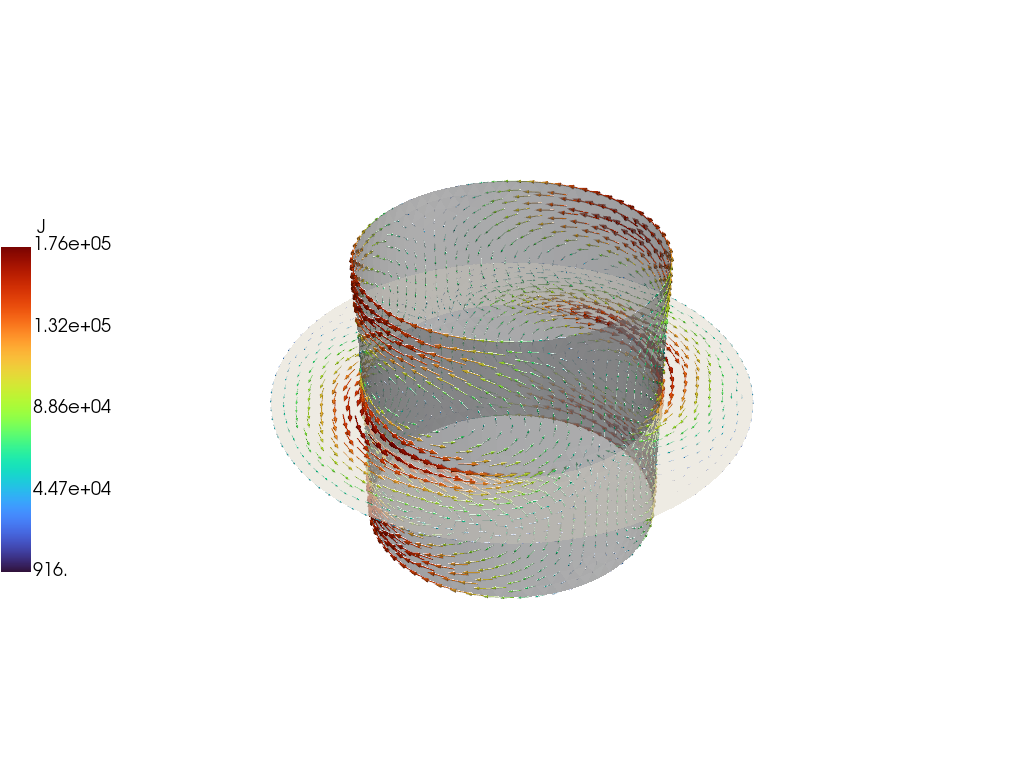

In [8]:
tw_ring.save_current(eig_vecs_ring[6,:],'J_07')
plot_data = tw_ring.build_XDMF()
if have_pyvista:
    grid = plot_data['ThinCurr']['smesh'].get_pyvista_grid()
    J_07 = plot_data['ThinCurr']['smesh'].get_field('J_07_v')
    grid["vectors"] = J_07
    grid.set_active_vectors("vectors")
    p = pyvista.Plotter()
    scale = 0.1/(np.linalg.norm(J_07,axis=1)).max()
    arrows = grid.glyph(scale="vectors", orient="vectors", factor=scale)
    p.add_mesh(arrows, cmap="turbo", scalar_bar_args={'title': "J", "vertical": True, "position_y":0.25, "position_x": 0.0})
    p.add_mesh(grid, color="white", opacity=0.6, show_edges=False)
    p.show(jupyter_backend='static')